# E95 · Election night: how each call reshapes the 2026 forecast

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: E94's data and its corrected frozen forecast of the 2026 US midterms (see E94 for sources and licences), and a log of the race calls made on election night, 3 November 2026, by the AP and the networks, entered by hand from their live pages (one small CSV that grows through the night) |
| **You will learn** | A **race call as data**: an interval on the true margin, with the race's own noise integrated out · **importance reweighting** of a frozen posterior, with the **effective sample size** as the warning light · the same update as a **PyMC refit** with a `Potential` · replaying the night **snapshot by snapshot**, and **what each call did** on its own · what the **latest calls** changed in every other race, and what they would have changed had they gone the other way · reading **"too close to call"** and **partial counts**, whose lean depends on the order the ballots are counted · **conditional forecasts** for the races still out |

## The night at a glance

The gauges show the chance that the Democrats win each chamber at the latest snapshot of the night,
from the refitted model; the gold tick is the frozen eve forecast. Below each gauge is the distribution
of Democratic seats, coloured by which side of the majority line it falls on. They are drawn at the end
of the run and placed here.

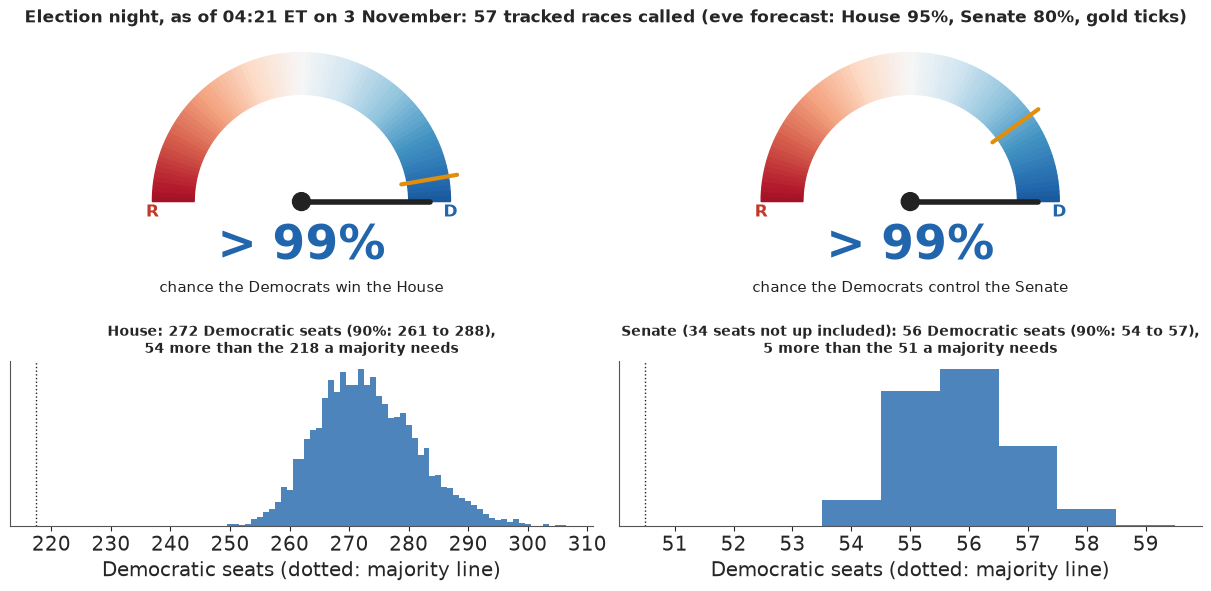

In [1]:
from IPython.display import Markdown, display

GLANCE = display(Markdown("*The gauges are drawn at the end of the run, from the latest snapshot.*"), display_id=True)

## The setting

E94 froze a forecast of the 2026 midterms on the afternoon of election day: 237 Democratic House seats
with a 0.94 chance of a majority, and 52 Democratic-caucus Senate seats with a 0.78 chance of control.
Then the polls closed, and the calls began. Each call settles one race, but it also says something about
all the others. Every race in the forecast shares one national environment and one polling error, and
the races in a state share a state effect, so a Democratic win in Florida's 25th district is evidence
about Ohio's Senate race. This notebook follows the night as it happens: after each new batch of calls,
what changed, where, and why.

The tool is Bayes' rule applied to a forecast that already exists: the frozen posterior is the prior,
and each call is a new observation. Election-night models do this (the *New York Times* "needle"
updates from precinct returns; Cohn 2016), and it is the same idea as the nowcasts from partial data in
E38 and E90. Two things make it a lesson rather than a lookup. A **call** is not a margin: it says only
that the winner is far enough ahead for the AP to be sure. That is an interval on the margin, and its
likelihood needs care. And there are two ways to update. **Importance reweighting** keeps the frozen
draws and weights each by the likelihood of the night's results; it is instant and exact, but it fails
when the results are surprising. A **refit** adds the results to the model and samples again, which
takes half a minute here. We use the first for quick questions and the second for the answers.

The notebook is rebuilt through the night as calls come in. Every number about the night (tables,
figures and the bulletin at the end) is computed from the call log; the prose describes the method, the
frozen eve, and the patterns that do not depend on which calls have come in.

| part | question | tool |
|---|---|---|
| 1 | Can we rebuild the frozen eve exactly? | E94's own model code and seed |
| 2 | What does one call say? | a call as an interval; importance weights and their ESS; a refit with a `Potential` |
| 3 | How has the night moved the forecast? | the call log replayed snapshot by snapshot; each call's own effect |
| 4 | What did the latest calls change? | the previous snapshot against the latest, race by race and on a map; the closest new call reversed |
| 5 | What is still out, and what does each race decide? | conditional control probabilities |
| 6 | Silences and partial counts | "too close to call" as an interval; margins, and the order ballots are counted |
| 7 | Where the night stands | a bulletin computed from the latest snapshot |

In [2]:
import contextlib
import gzip
import hashlib
import io
import json
import logging
import os
import sys
import time
import warnings

for name in ("OPENBLAS_NUM_THREADS", "OMP_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(name, "1")  # before NumPy: one BLAS thread per chain
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # nothing here uses a GPU

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.collections import LineCollection, PolyCollection
from matplotlib.patches import Circle, Wedge
from scipy.stats import gaussian_kde, norm

from pymc_challenges import data

sys.modules.pop("jax", None)   # ArviZ's lazy JAX stub would import all of JAX for nothing (see E89 and E94)

RANDOM_SEED = 95
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, message=".*tight.*")
warnings.filterwarnings("ignore", message=".*sample_stats.*")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
T_START = time.time()
D_C, R_C, INK, MUTED, LIGHT, GOLD = "#2166ac", "#c0392b", "#222222", "#8a8a8a", "#d9d9d9", "#e08e0b"
TIMES = {}

## 1 · The eve, rebuilt

The update needs the frozen posterior itself, not just its summaries: every draw of the national
margin, the polling error, the state effects and each race's mean. E94 froze only summaries, so we
rebuild the posterior with E94's own code. The cell below runs E94's sections 1 to 3.2 (the data, the
midterm prior and the model functions) from its source file, quietly, and then calls E94's
`fit_cycle(2026)` with E94's seed. The data files are the ones whose hashes the frozen file records, so
this is the same posterior, sampled the same way.

In [3]:
E94_SRC = data.DATA_DIR.parent / "notebook_src/examples/E94_midterms_polls_money.py"


def load_e94():
    """Run E94's sections 1 to 3.2 (data, prior, model code), quietly, and return its namespace."""
    src = E94_SRC.read_text()
    cut = src.index("# ### 3.3 Failure 1")
    ns = {"__name__": "e94"}
    with contextlib.redirect_stdout(io.StringIO()):
        exec(compile(src[: src.rindex("# %%", 0, cut)], str(E94_SRC), "exec"), ns)
    plt.close("all")
    return ns


E94 = load_e94()
prepare, build_model, simulate, seats, fit_cycle = (E94[k] for k in ("prepare", "build_model", "simulate", "seats",
                                                                     "fit_cycle"))
t0 = time.time()
eve = fit_cycle(2026, keep=True)           # E94's own call, with E94's seed: the same draws as its section 7
TIMES["eve fit"] = time.time() - t0
d = eve["d"]
tm, tgt = d["tm"], d["tgt"]
FROZEN = json.load(open(data.path("e94_freeze_2026_v2")))
fz = pd.DataFrame(FROZEN["races"]).set_index("race")
for fname, h in FROZEN["inputs_sha256_content"].items():
    b = (data.DATA_DIR / fname).read_bytes()
    same = hashlib.sha256(gzip.decompress(b) if fname.endswith(".gz") else b).hexdigest() == h
    print(f"input {fname:20s} {'as frozen' if same else 'CHANGED since the freeze'}")
notup = {k: int(v) for k, v in E94["build_log"]["senate_2026_not_up"].items()}
NOT_UP = notup["Democratic"] + notup["Independent"]
s_ = eve["seats"]
gap = np.abs((eve["sim"] > 0).mean(0) - fz.loc[tm.race, "pD"].to_numpy())
print({k: eve[k] for k in ("divergences", "max r_hat", "min ESS")})
print(f"P(D) against the frozen v2 file: mean difference {gap.mean():.3f}, largest {gap.max():.2f}")
print(f"House D seats {np.median(s_['H']):.0f}, P(majority) {(s_['H'] >= 218).mean():.2f} (frozen "
      f"{FROZEN['seats']['H']['P_D_control']:.2f}); Senate D caucus {np.median(s_['S'] + NOT_UP):.0f}, "
      f"P(control) {(s_['S'] + NOT_UP >= 51).mean():.2f} (frozen {FROZEN['seats']['S']['P_D_control']:.2f})")

input e94_races.csv        as frozen
input e94_polls.csv        as frozen
input e94_reports.csv.gz   as frozen
input e94_ie.csv.gz        as frozen
input e94_pollerr.csv      as frozen
{'divergences': 0, 'max r_hat': 1.011, 'min ESS': 347}
P(D) against the frozen v2 file: mean difference 0.002, largest 0.04
House D seats 237, P(majority) 0.94 (frozen 0.94); Senate D caucus 52, P(control) 0.79 (frozen 0.78)


The inputs are unchanged, the sampler is clean, and the rebuilt forecast matches the frozen file: race
chances differ by 0.002 on average and at most 0.04 (the frozen file came from a separate run of the
same code), and the control probabilities agree to the second decimal.

For the update we need each draw's **mean** margin in every race, before the race's own noise. In
E94's model a race with polls has its margin $m_r$ as a parameter, so the sampler already holds it. A
race without polls has margin

$$m_r = \mu_r(\theta) + \sigma_{o(r)}\,\varepsilon_r, \qquad \varepsilon_r \sim \mathrm{Normal}(0, 1),$$

where $\mu_r(\theta)$ collects the national margin, the office intercept, the fundamentals and the
state effect, and $\sigma_{o(r)}$ is the race-level sd of its office. E94's `simulate` adds the noise
by drawing $\varepsilon_r$; here we keep $\mu_r$ and $\sigma_{o(r)}$ separately for all 4,000 draws, so
that the noise can be integrated out exactly.

In [4]:
def eve_draws(d, idata):
    """Every posterior draw's mean margin and race-level sd for each modelled race (no race noise added).

    For a polled race the sampler already holds its margin (m_pol, noise included), so its sd is 0."""
    tm = d["tm"]
    post = az.extract(idata)
    n = post.sizes["sample"]
    isS = (tm.office == "S").to_numpy().astype(int)
    X = np.broadcast_to(np.c_[tm.leanx, tm.inc, np.nan_to_num(tm.money.to_numpy())], (n, len(tm), 3)).copy()
    st = tm.state.map({s: i for i, s in enumerate(d["states"])}).to_numpy()
    T = lambda v, *dims: post[v].transpose("sample", *dims).values  # noqa: E731
    if len(d["miss"]):
        X[:, d["miss"], 2] = T("money_missing", "missing_race")
    icpt = post["N"].values[:, None] + T("gamma", "office") + post["s_int"].values[:, None] * T("z_int_t", "office")
    mu = (icpt[:, isS] + (T("beta", "office", "x")[:, isS, :] * X).sum(-1)
          + (T("z_st_t", "state") * post["s_state"].values[:, None])[:, st])
    sd = np.broadcast_to(T("sig", "office")[:, isS], mu.shape).copy()
    pol_i = np.array([tm.index[tm.race == r][0] for r in d["polled"]])
    mu[:, pol_i], sd[:, pol_i] = T("m_pol", "polled"), 0.0
    return {"mu": mu, "sd": sd, "N": post["N"].values, "bias": post["bias"].values}


E = eve_draws(d, eve["idata"])
RACE = {r: i for i, r in enumerate(tm.race)}
U = np.random.default_rng(RANDOM_SEED).random(E["mu"].shape)     # common random numbers for every outcome draw
p_eve = norm.cdf(E["mu"] / np.where(E["sd"] > 0, E["sd"], 1e-9)).mean(0)
print(f"{E['mu'].shape[0]} draws x {E['mu'].shape[1]} races ({len(d['polled'])} with polls); P(D) from the means "
      f"against the frozen file: largest difference {np.abs(p_eve - fz.loc[tm.race, 'pD']).max():.3f}")

4000 draws x 451 races (104 with polls); P(D) from the means against the frozen file: largest difference 0.040


## 2 · What one call says

What does "the AP called Georgia for Ossoff" tell us about the model? It says the true margin is
positive. We soften the edge a little, because the AP is occasionally wrong and because a margin of
exactly zero is not special: the likelihood of a call for the Democrat is

$$P(\text{call D} \mid \theta) = P(m_r > 0 \mid \theta) = \Phi\!\left(\frac{\mu_r(\theta)}{\sqrt{\sigma_{o(r)}^2 + \tau^2}}\right),$$

with $\tau = 0.5$ points. For a race without polls the race noise is integrated out, which is why
$\sigma_{o(r)}$ appears; for a race with polls $m_r$ is a parameter and only $\tau$ remains. A call for
the Republican uses $\Phi(-\mu_r/\cdot)$, and section 6 adds "too close to call" as an interval around
zero.

**Importance reweighting.** The frozen posterior $p(\theta \mid \text{polls})$ becomes
$p(\theta \mid \text{polls}, \text{calls}) \propto p(\theta \mid \text{polls})\, P(\text{calls} \mid \theta)$,
so the frozen draws stay valid if each is weighted by $w_s \propto \prod_r P(\text{call}_r \mid \theta_s)$.
This is exact for the same reason as E94's prior reweighting: only a factor of the posterior changes.
What can go wrong is the sample, not the algebra. If a few draws carry all the weight, the weighted
average rests on those few. The effective sample size $\mathrm{ESS} = 1/\sum_s w_s^2$ (weights summing
to one) counts how many equally weighted draws the weighted sample is worth.

Forecasts after a call also need each race's chance given the draw and the call: 1 or 0 for a called
race, the truncated normal's share above zero for a race known to be close, and
$\Phi(\mu_r/\sigma_{o(r)})$ otherwise. Seat totals come from one simulated election per draw, using the
same uniform random numbers in every scenario, so that differences between scenarios are not noise.

The first call of the night, Georgia's Senate race for Ossoff, makes a good first example, together
with the call that did not happen.

In [5]:
TAU = 0.5     # points: how far on the wrong side of zero a called race could still be (a soft edge)
CLOSE = 3.0   # points: "too close to call" read as |margin| < CLOSE (an assumption, varied in section 6)
FINAL = 95    # a race counts as counted once this share of the expected vote is in; its margin is then data
SKEW = 30.0   # points: how differently the ballots still out could lean from those counted (any direction)


def tau_m(pct_in):
    """sd of a counted margin around the final one: counting noise plus the skew of the uncounted share."""
    return float(np.hypot(0.5, SKEW * (1 - pct_in / 100)))


def info_from(calls, close=CLOSE):
    """One row per race with information: the interval (lo, hi) its true margin lies in."""
    rows = []
    for r in calls.itertuples():
        if r.status == "called":
            rows.append((r.race, 0.0, np.inf) if r.winner == "D" else (r.race, -np.inf, 0.0))
        elif r.status == "too close":
            rows.append((r.race, -close, close))
    return rows


def margins_from(calls):
    """(race, two-party margin, its sd) for the races counted to at least FINAL percent."""
    ok = calls[(calls.pct_expected_in >= FINAL) & calls.d_pct.notna() & calls.r_pct.notna()]
    return [(r.race, 100 * (r.d_pct - r.r_pct) / (r.d_pct + r.r_pct), tau_m(r.pct_expected_in))
            for r in ok.itertuples()]


def loglik(mu, sd, lo, hi):
    """log P(lo < margin < hi) for margin ~ Normal(mu, sqrt(sd^2 + TAU^2)), per draw."""
    s = np.sqrt(sd**2 + TAU**2)
    if np.isinf(hi):
        return norm.logcdf((mu - lo) / s)
    if np.isinf(lo):
        return norm.logcdf((hi - mu) / s)
    return np.log(np.clip(norm.cdf((hi - mu) / s) - norm.cdf((lo - mu) / s), 1e-300, None))


def weights(E, info):
    lw = np.zeros(E["mu"].shape[0])
    for race, lo, hi in info:
        i = RACE[race]
        lw += loglik(E["mu"][:, i], E["sd"][:, i], lo, hi)
    w = np.exp(lw - lw.max())
    return w / w.sum()


def ess(w):
    return 1.0 / np.sum(w**2)


def outcome_probs(E, info):
    """P(D wins the race | draw, information): 1 or 0 for a called race, truncated for a close one."""
    p = norm.cdf(E["mu"] / np.where(E["sd"] > 0, E["sd"], 1e-9))
    for race, lo, hi in info:
        i = RACE[race]
        s = np.sqrt(E["sd"][:, i] ** 2 + TAU**2)
        a, b = norm.cdf((lo - E["mu"][:, i]) / s), norm.cdf((hi - E["mu"][:, i]) / s)
        z = norm.cdf(-E["mu"][:, i] / s)
        p[:, i] = np.clip((b - np.clip(z, a, b)) / np.clip(b - a, 1e-300, None), 0, 1)
    return p


def summarise(E, info, w=None):
    """Weighted forecast: per-race P(D), one simulated election per draw, and control of each chamber."""
    w = np.full(E["mu"].shape[0], 1 / E["mu"].shape[0]) if w is None else w
    p = outcome_probs(E, info)
    won = U < p
    st = seats(d, np.where(won, 1.0, -1.0))
    sen = st["S"] + NOT_UP
    return {"w": w, "ess": ess(w), "pD": w @ p, "won": won, "H": st["H"], "S": sen,
            "P(House)": float(w @ (st["H"] >= 218)), "P(Senate)": float(w @ (sen >= 51)),
            "N": E["N"], "bias": E["bias"]}


def reweighted(info):
    return summarise(E, info, weights(E, info))


def wq(x, w, qs=(0.05, 0.5, 0.95)):
    o = np.argsort(x)
    c = np.cumsum(w[o])
    return np.interp(qs, c - w[o] / 2, x[o])


def line(lab, S):
    iv = lambda v, f: "{1:{f}} [{0:{f}}, {2:{f}}]".format(*wq(v, S["w"]), f=f)  # noqa: E731
    return {"": lab, "ESS": round(S["ess"]), "P(D House)": round(S["P(House)"], 3),
            "P(D Senate)": round(S["P(Senate)"], 3), "House seats": iv(S["H"], ".0f"),
            "Senate seats": iv(S["S"], ".0f"), "N": iv(S["N"], "+.1f"), "polling error": iv(S["bias"], "+.1f")}


EVE = summarise(E, [])
S_GA, S_GAR = reweighted([("GA-S", 0.0, np.inf)]), reweighted([("GA-S", -np.inf, 0.0)])
print(pd.DataFrame([line("eve (frozen posterior)", EVE), line("Georgia called for Ossoff", S_GA),
                    line("if Georgia had gone to Collins", S_GAR)]).set_index("").to_string())
sen_rows = tm.index[tm.office == "S"]
dp = pd.DataFrame({"race": tm.race[sen_rows], "eve": EVE["pD"][sen_rows], "GA called D": S_GA["pD"][sen_rows],
                   "GA to R": S_GAR["pD"][sen_rows]})
print(f"largest move in another Senate race's P(D) from the Ossoff call: "
      f"{(dp['GA called D'] - dp.eve)[dp.race != 'GA-S'].abs().max():.4f}")

                                 ESS  P(D House)  P(D Senate)     House seats Senate seats                   N       polling error
                                                                                                                                  
eve (frozen posterior)          4000       0.946        0.801  237 [217, 262]  52 [48, 56]  +8.0 [+3.2, +12.8]   +1.0 [-3.7, +5.9]
Georgia called for Ossoff       3987       0.948        0.804  237 [217, 262]  52 [49, 56]  +8.0 [+3.2, +12.8]   +1.0 [-3.7, +5.8]
if Georgia had gone to Collins    16       0.422        0.139  215 [201, 243]  47 [44, 52]  +2.2 [-0.9, +10.1]  +7.3 [-0.5, +11.0]
largest move in another Senate race's P(D) from the Ossoff call: 0.0016


The frozen forecast gave Ossoff a 0.994 chance (median D+14), so his win was almost no news: the
chance of a Democratic House goes from 0.946 to 0.948, of a Democratic Senate from 0.801 to 0.804, and
no other Senate race moves by more than 0.002. The weights barely vary (ESS 3,987 of 4,000), because
only the 26 draws in which Ossoff loses are down-weighted.

The last row asks the opposite question. A Collins win had a 0.0065 chance, and it would have said a
great deal: the polling error would jump from +1.0 to about +7 points (the polls far too Democratic),
and both chambers would tilt Republican. But its ESS is 16, so the whole answer rests on the handful of
draws in which Ossoff lost, and the numbers in that row are rough. That is the warning light working.
A surprising result is exactly the one reweighting cannot handle, and the refit below can.

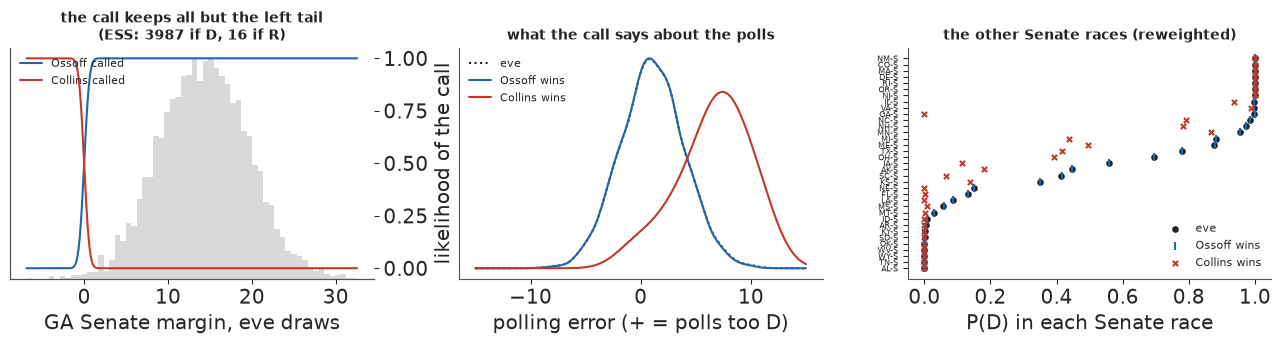

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
ax = axes[0]
g_i = RACE["GA-S"]
ax.hist(E["mu"][:, g_i], bins=60, color=LIGHT, density=True)
ax.set_xlabel("GA Senate margin, eve draws")
ax.set_yticks([])
ax2 = ax.twinx()
gm = np.linspace(E["mu"][:, g_i].min(), E["mu"][:, g_i].max(), 300)
ax2.plot(gm, norm.cdf(gm / TAU), color=D_C, label="Ossoff called")
ax2.plot(gm, norm.cdf(-gm / TAU), color=R_C, label="Collins called")
ax2.set_ylabel("likelihood of the call")
ax2.legend(fontsize=8, loc="upper left")
ax.set_title(f"the call keeps all but the left tail\n(ESS: {S_GA['ess']:.0f} if D, {S_GAR['ess']:.0f} if R)",
             fontsize=10)
ax = axes[1]
gx = np.linspace(-15, 15, 200)
for lab, S, c, ls in (("eve", EVE, INK, ":"), ("Ossoff wins", S_GA, D_C, "-"), ("Collins wins", S_GAR, R_C, "-")):
    ax.plot(gx, gaussian_kde(S["bias"], weights=S["w"])(gx), color=c, ls=ls, label=lab)
ax.set_xlabel("polling error (+ = polls too D)")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title("what the call says about the polls", fontsize=10)
ax = axes[2]
o = np.argsort(dp.eve.to_numpy())
ax.scatter(dp.eve.to_numpy()[o], np.arange(len(o)), color=INK, s=14, label="eve")
ax.scatter(dp["GA called D"].to_numpy()[o], np.arange(len(o)), color=D_C, s=40, marker="|", label="Ossoff wins")
ax.scatter(dp["GA to R"].to_numpy()[o], np.arange(len(o)), color=R_C, s=14, marker="x", label="Collins wins")
ax.set_yticks(range(len(o)), dp.race.to_numpy()[o], fontsize=6)
ax.set_xlabel("P(D) in each Senate race")
ax.legend(fontsize=8, loc="lower right")
ax.set_title("the other Senate races (reweighted)", fontsize=10)
fig.tight_layout();

On the left, the eve draws of Georgia's margin (grey) sit almost entirely right of zero, where the
likelihood of an Ossoff call (blue) is 1, so the call removes only a sliver of the left tail; a Collins
call (red) would have kept only that sliver. In the middle, the Ossoff curve lies on the eve's. On the
right, the red crosses show how far a Georgia upset would have dragged every competitive race, through
the shared polling error and the national margin. **A call moves the rest of the map in proportion to
its surprise**, and the surprise of a result, $-\log P(\text{result})$ under the forecast, is the measure
we carry through the night.

### 2.1 The same update by NUTS

The refit adds the night's results to E94's model as one `pm.Potential`, the sum of the log
likelihoods of all calls. For a race with polls the Potential is a function of the parameter $m_r$; for
a race without polls it is a function of $\mu_r(\theta)$, built from the model's own variables, with
the race noise integrated out as above. `pm.logcdf` of a standard normal keeps the tails stable, and
`pm.math.logdiffexp` gives the log probability of an interval. A race counted to 95% or more also gets
its margin as data (section 6).

In [7]:
def night_fit(d, info=(), margins=(), seed=RANDOM_SEED):
    """Refit E94's 2026 model with the night's results as extra likelihood terms.

    info: (race, lo, hi) intervals on the true margin; margins: (race, observed two-party margin, its sd)."""
    m = build_model(d)
    tm = d["tm"]
    isS = (tm.office == "S").to_numpy().astype(int)
    st = tm.state.map({s: i for i, s in enumerate(d["states"])}).to_numpy()
    miss = list(d["miss"])
    std = pm.Normal.dist(0, 1)
    with m:
        def mean_sd(race):
            i = RACE[race]
            if race in d["polled"]:
                return m["m_pol"][d["polled"].index(race)], 0.0
            o = isS[i]
            money = m["money_missing"][miss.index(i)] if i in miss else pt.as_tensor(float(tm.money.iloc[i]))
            x = pt.stack([pt.as_tensor(float(tm.leanx.iloc[i])), pt.as_tensor(float(tm.inc.iloc[i])), money])
            mu = (m["N"] + m["gamma"][o] + m["s_int"] * m["z_int_t"][o] + (m["beta"][o] * x).sum()
                  + m["s_state"] * m["z_st_t"][st[i]])
            return mu, m["sig"][o]

        terms = []
        for race, lo, hi in info:
            mu, sd = mean_sd(race)
            s = pt.sqrt(sd**2 + TAU**2)
            if np.isinf(hi):
                terms.append(pm.logcdf(std, (mu - lo) / s))
            elif np.isinf(lo):
                terms.append(pm.logcdf(std, (hi - mu) / s))
            else:
                terms.append(pm.math.logdiffexp(pm.logcdf(std, (hi - mu) / s), pm.logcdf(std, (lo - mu) / s)))
        for race, y, m_sd in margins:
            mu, sd = mean_sd(race)
            terms.append(pm.logp(pm.Normal.dist(mu, pt.sqrt(sd**2 + m_sd**2)), y))
        pm.Potential("night", pt.sum(pt.stack(terms)))
        idata = pm.sample(random_seed=seed, progressbar=False, target_accept=0.9)
    return idata


def refit(info, margins=()):
    idt = night_fit(d, info, margins)
    S = summarise(eve_draws(d, idt), info)
    S["diag"] = E94["diagnostics"](idt)
    return S

## 3 · The night, call by call

The calls come from the outlets' live pages, entered by hand into a log: one row each time a race is
called or listed as too close, with the outlet, the time of the snapshot and the source. A race's
latest row is its current state, so the log can be replayed: the forecast at any snapshot uses the rows
up to that time. Only Senate races and the competitive House races (a frozen chance between 0.05 and
0.95) are entered, because a safe seat called as expected carries no information.

A call is a projection, not a count: the AP declares a winner when its analysts are sure who leads,
often with most of the vote uncounted, and their models know which ballots are still out. Partial
counts are a different matter, taken up in section 6.

In [8]:
data.describe("e95_calls_2026")
log = data.load("e95_calls_2026")
log["t"] = pd.to_datetime(log.as_of_et)
log = log.sort_values("t", kind="stable").reset_index(drop=True)
SNAPS = sorted(log.t.unique())


def state_at(t):
    """Each race's latest row at time t: the night's information as of that snapshot."""
    return log[log.t <= t].groupby("race", sort=False).tail(1).reset_index(drop=True)


calls = state_at(SNAPS[-1]).join(fz[["pD", "pred", "q10", "q90"]], on="race")
calls["P(result)"] = np.where(calls.winner == "D", calls.pD, 1 - calls.pD)
calls["surprise"] = (-np.log(np.clip(calls["P(result)"], 1e-4, 1))).where(calls.status == "called")
AS_OF = SNAPS[-1].strftime("%Y-%m-%d %H:%M")
INFO, MARG = info_from(calls), margins_from(calls)
closes = calls[calls.status == "too close"].race.tolist()
print(f"{len(log)} rows in the log, {len(SNAPS)} snapshots; latest {AS_OF} ET: "
      f"{int((calls.status == 'called').sum())} races called, {len(closes)} too close to call")
print(calls[["race", "status", "winner", "reported_by", "as_of_et", "pD", "pred", "surprise"]]
      .sort_values("surprise", ascending=False).round(3).to_string(index=False))

e95_calls_2026: A log: one row each time a race is called or listed as too close; a race's latest row is its state. race (as in e94_races), status (called or too close), winner (D or R), reported_by, as_of_et (the snapshot), the partial count where one was given (d_pct, r_pct, pct_expected_in), source_url.
  source: Election-night race calls (projections by the AP and the networks, not certified results) for the 2026 US midterms, entered by hand from the outlets' live pages named in each row; a snapshot that grows through the night.
  url:    https://abcnews.com/Politics/live-updates/midterm-elections-live-updates/?id=137782085
61 rows in the log, 11 snapshots; latest 2026-11-04 04:21 ET: 57 races called, 1 too close to call
 race    status winner                         reported_by         as_of_et    pD    pred  surprise
IN-05    called      D                                  AP 2026-11-04 02:21 0.180  -5.239     1.715
OH-15    called      D                                  AP 2026-1

The table is sorted by surprise. The races at the bottom were called as expected and carry almost no
information; the ones at the top are where the night has said something the forecast did not already
know. Upsets, if there are any, are at the top with a surprise above 1 (a result the forecast gave
less than a 0.37 chance).

### 3.1 Replaying the night

The cell replays the log: for each snapshot, the forecast reweighted by every call up to that time, with
its ESS. The latest snapshot is also refitted by NUTS, and the two are compared; when they agree, the
reweighted path can be trusted, and when the ESS falls below a few hundred, only the refit counts.

In [9]:
path = [{"snapshot": "eve", **{k: v for k, v in line("", EVE).items() if k}}]
S_snap = {}
for t in SNAPS:
    S_snap[t] = reweighted(info_from(state_at(t)))
    path.append({"snapshot": t.strftime("%H:%M"), **{k: v for k, v in line("", S_snap[t]).items() if k}})
path = pd.DataFrame(path)
t0 = time.time()
S_CALLS = refit(INFO)                                 # the latest calls, by NUTS
S0 = refit(INFO, MARG) if MARG else S_CALLS            # the night's forecast: calls, and margins where counted
TIMES["latest refits"] = time.time() - t0
print(path.to_string(index=False))
print("refit at the latest snapshot:", S_CALLS["diag"])
rows = [line(f"{AS_OF[-5:]}: reweighted", S_snap[SNAPS[-1]]), line(f"{AS_OF[-5:]}: NUTS refit", S_CALLS)]
if MARG:
    rows.append(line(f"{AS_OF[-5:]}: refit with counted margins", S0))
    print("counted margins used:", {r: (round(y, 1), round(s, 1)) for r, y, s in MARG})
print(pd.DataFrame(rows).set_index("").to_string())
gap = np.abs(S_snap[SNAPS[-1]]["pD"] - S_CALLS["pD"])
print(f"reweighted against refit, P(D) per race: mean |difference| {gap.mean():.4f}, largest {gap.max():.3f}")

snapshot  ESS  P(D House)  P(D Senate)    House seats Senate seats                    N     polling error
     eve 4000       0.946        0.801 237 [217, 262]  52 [48, 56]   +8.0 [+3.2, +12.8] +1.0 [-3.7, +5.9]
   20:20 1131       0.989        0.926 243 [225, 265]  54 [50, 57]   +9.4 [+5.4, +13.5] -0.3 [-4.4, +3.8]
   20:50 2410       0.986        0.867 239 [222, 261]  53 [49, 56]   +8.4 [+4.3, +12.5] +0.6 [-3.4, +4.6]
   21:28 2410       0.986        0.867 239 [222, 261]  53 [49, 56]   +8.4 [+4.3, +12.5] +0.6 [-3.4, +4.6]
   23:18  302       1.000        1.000 254 [240, 271]  55 [53, 57]  +11.3 [+8.0, +14.5] -2.3 [-5.3, +0.9]
   23:45  114       1.000        1.000 261 [248, 276]  56 [54, 57]  +12.4 [+9.8, +14.9] -3.5 [-5.8, -0.8]
   00:18   72       1.000        1.000 262 [248, 278]  56 [55, 58]  +12.8 [+9.8, +16.2] -3.7 [-6.6, -1.1]
   00:30   66       1.000        1.000 262 [248, 278]  56 [55, 58]  +12.9 [+9.8, +16.2] -3.8 [-6.7, -1.1]
   01:21   30       1.000        1.000 264 [25

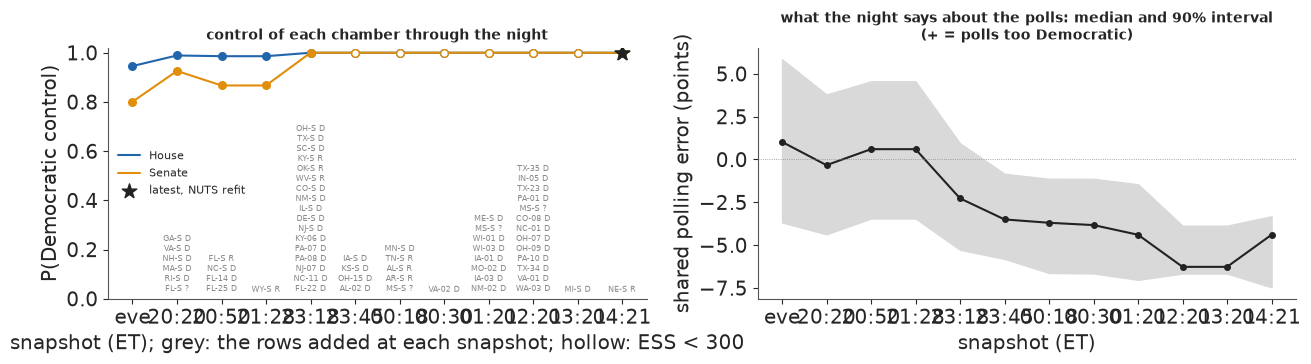

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
xs = np.arange(len(path))
lab_x = path.snapshot.tolist()
ok = path.ESS.to_numpy() >= 300
ax = axes[0]
for key, c in (("P(D House)", D_C), ("P(D Senate)", GOLD)):
    ax.plot(xs, path[key], color=c, lw=1.5, label=key.replace("P(D ", "").rstrip(")"))
    ax.scatter(xs[ok], path[key][ok], color=c, s=30, zorder=3)
    ax.scatter(xs[~ok], path[key][~ok], facecolor="white", edgecolor=c, s=30, zorder=3)
ax.scatter([xs[-1]] * 2, [S0["P(House)"], S0["P(Senate)"]], marker="*", s=120, color=INK, zorder=4,
           label="latest, NUTS refit")
for k, t in enumerate(SNAPS, start=1):
    new = log[log.t == t]
    txt = "\n".join(f"{r.race} {'?' if r.status == 'too close' else r.winner}" for r in new.itertuples())
    ax.text(k, 0.02, txt, fontsize=6, ha="center", va="bottom", color=MUTED)
ax.set_xticks(xs, lab_x)
ax.set_ylim(0, 1.02)
ax.set_ylabel("P(Democratic control)")
ax.set_xlabel("snapshot (ET); grey: the rows added at each snapshot; hollow: ESS < 300")
ax.legend(fontsize=8, loc="center left")
ax.set_title("control of each chamber through the night", fontsize=10)
ax = axes[1]
qs = np.array([wq(S["bias"], S["w"]) for S in [EVE] + [S_snap[t] for t in SNAPS]])
ax.fill_between(xs, qs[:, 0], qs[:, 2], color=LIGHT)
ax.plot(xs, qs[:, 1], color=INK, marker="o", ms=4)
ax.axhline(0, color=MUTED, lw=0.6, ls=":")
ax.set_xticks(xs, lab_x)
ax.set_ylabel("shared polling error (points)")
ax.set_xlabel("snapshot (ET)")
ax.set_title("what the night says about the polls: median and 90% interval\n(+ = polls too Democratic)",
             fontsize=10)
fig.tight_layout();

The left panel is the night in one picture: the chance of each chamber after each snapshot, with the
races added at that snapshot written underneath. The right panel shows why it moves: each call nudges
the shared polling error, and through it every race not yet called. A night of expected calls tightens
the interval a little and leaves the median in place; a night that runs ahead of the forecast for one
party pushes the median away from the eve's +1. The jumps on the left are rarely from the races that
settle a seat directly. They come from the calls that say the polls were off.

### 3.2 What each call did

How much of the movement is owed to each call? With reweighting this is a quick question: remove one
call from the latest snapshot, and see how much the chance of each chamber falls back. This is not an
additive decomposition (calls overlap in what they say about the polling error), but it ranks them.

 race    result  P(result) on the eve  surprise  House  Senate
 NE-S         R                0.8565    0.1549   -0.0    -0.0
 MA-S         D                1.0000   -0.0000    0.0     0.0
WA-03         D                0.7655    0.2672    0.0     0.0
 NH-S         D                0.9740    0.0263   -0.0    -0.0
 WY-S         R                1.0000   -0.0000   -0.0    -0.0
 FL-S         R                0.8625    0.1479   -0.0    -0.0
FL-25         D                0.7915    0.2338   -0.0    -0.0
 KY-S         R                0.9970    0.0030   -0.0    -0.0
 RI-S         D                1.0000   -0.0000   -0.0    -0.0
 VA-S         D                0.9985    0.0015   -0.0    -0.0
NC-11         D                0.8340    0.1815   -0.0    -0.0
PA-07         D                0.7765    0.2530   -0.0    -0.0
 NJ-S         D                1.0000   -0.0000   -0.0    -0.0
 OK-S         R                1.0000   -0.0000   -0.0    -0.0
 WV-S         R                1.0000   -0.0000    0.0 

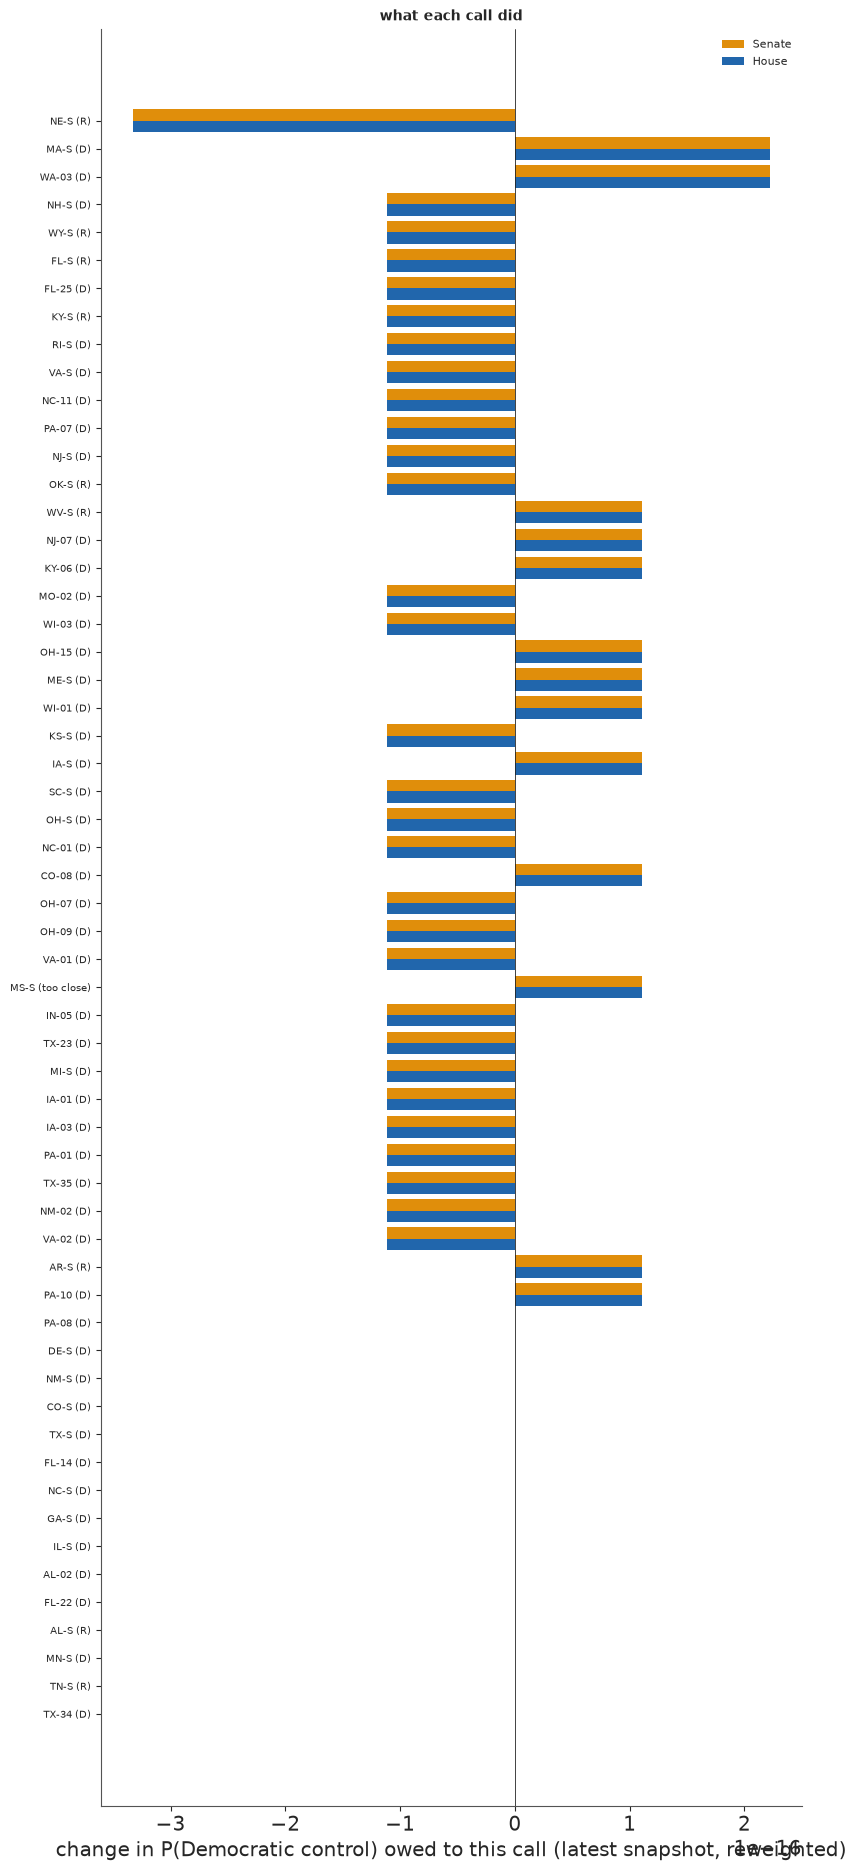

In [11]:
base = S_snap[SNAPS[-1]]
eff = []
for r in calls.itertuples():
    rest = [x for x in INFO if x[0] != r.race]
    S = reweighted(rest)
    eff.append({"race": r.race, "result": "too close" if r.status == "too close" else r.winner,
                "surprise": r.surprise,
                "House": base["P(House)"] - S["P(House)"], "Senate": base["P(Senate)"] - S["P(Senate)"]})
eff = pd.DataFrame(eff)
eff.insert(2, "P(result) on the eve", calls["P(result)"].where(calls.status == "called").to_numpy())
eff = eff.reindex((eff.House.abs() + eff.Senate.abs()).sort_values(ascending=False).index)
print(eff.round(4).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 0.3 * len(eff) + 1.2))
y_ = np.arange(len(eff))[::-1]
ax.barh(y_ + 0.2, eff.Senate, height=0.4, color=GOLD, label="Senate")
ax.barh(y_ - 0.2, eff.House, height=0.4, color=D_C, label="House")
ax.axvline(0, color=INK, lw=0.6)
ax.set_yticks(y_, [f"{r} ({x})" for r, x in zip(eff.race, eff.result)], fontsize=7)
ax.set_xlabel("change in P(Democratic control) owed to this call (latest snapshot, reweighted)")
ax.legend(fontsize=8)
ax.set_title("what each call did", fontsize=10);

Expected calls sit near zero. The bars that matter belong to results the forecast thought less likely:
a Democratic win in a Republican-leaning seat lifts the Democrats' chances everywhere, a Republican win
in a seat the Democrats expected to take pulls them down, and a race listed as too close in a state one
party was expected to win easily acts like a small upset (section 6).

## 4 · What the latest calls changed

The bulletin of the night is the difference between the last two snapshots. Two refits would differ
by their own sampling noise, a couple of hundredths per race, which is as large as what one batch of
calls usually does. So the change is measured on the same 4,000 draws, reweighted for each snapshot:
the noise then cancels, and the difference is exactly what the new rows did (the ESS column of the
replay says whether the weights can be trusted). Late in the night that trust runs out: once the
latest snapshot's reweighting ESS falls below 300, a handful of draws carry all the weight and the
reweighted change is mostly noise. From then on the change is measured between two NUTS refits, the
previous snapshot's and the latest, and moves of a couple of hundredths should be read as noise. The
cell lists the races whose chances moved most and
maps the change in every Senate race (and, in section 4.1, every House district). It also asks how much the latest calls mattered: the closest race
called in the latest snapshot, or so far if none of the new calls was in doubt, had it gone the other
way, by refit.

In [12]:
PREV = SNAPS[-2] if len(SNAPS) > 1 else None
REFIT_ESS = 300
REFITTED = {}                                            # refits by snapshot, reused by the slider (7.1)
t0 = time.time()
if S_snap[SNAPS[-1]]["ess"] >= REFIT_ESS:
    MOVE_HOW = "reweighted"
    S_PREV = S_snap[PREV] if PREV is not None else EVE  # the same draws as the latest snapshot
    S_LAST = S_snap[SNAPS[-1]]
else:
    MOVE_HOW = "refit"
    if PREV is None:
        S_PREV = EVE
    else:
        st_prev = state_at(PREV)
        S_PREV = REFITTED[PREV] = refit(info_from(st_prev), margins_from(st_prev))
    S_LAST = S0
new_rows = log[log.t == SNAPS[-1]]
doubt = calls[(calls.status == "called") & calls.pD.between(0.02, 0.98)]   # a reversal must be possible
new_doubt = doubt[doubt.race.isin(new_rows.race)]
pool, FLIP_WHEN = (new_doubt, "the closest race called at the latest snapshot") if len(new_doubt) else \
    (doubt, "the closest race called so far (none of the latest calls was in doubt)")
flip = pool.assign(gap=(pool.pD - 0.5).abs()).sort_values("gap").race.iloc[0]
flip_win = calls.set_index("race").winner[flip]
INFO_F = [x for x in INFO if x[0] != flip] + [(flip, 0.0, np.inf) if flip_win == "R" else (flip, -np.inf, 0.0)]
S_FLIP = refit(INFO_F, [m_ for m_ in MARG if m_[0] != flip])
TIMES["counterfactual refit"] = time.time() - t0
prev_lab = PREV.strftime("%H:%M") if PREV is not None else "eve"
print(f"{MOVE_HOW} (latest reweighting ESS {S_snap[SNAPS[-1]]['ess']:.0f}), previous snapshot {prev_lab}: P(D House) {S_PREV['P(House)']:.3f}, P(D Senate) "
      f"{S_PREV['P(Senate)']:.3f}; latest {AS_OF[-5:]}: {S_LAST['P(House)']:.3f}, {S_LAST['P(Senate)']:.3f}")
print("rows added at the latest snapshot:", ", ".join(f"{r.race} {r.status} {r.winner if r.status == 'called' else ''}"
                                                    .strip() for r in new_rows.itertuples()))
called_now = set(calls.race[calls.status == "called"])
mv = pd.DataFrame({"race": tm.race, "office": tm.office, "eve": EVE["pD"], "previous": S_PREV["pD"], "latest": S_LAST["pD"]})
mv["change"] = mv.latest - mv.previous
mv = mv[~mv.race.isin(called_now)]
print(f"races not yet called that moved most since the previous snapshot ({prev_lab}):")
print(mv.reindex(mv.change.abs().sort_values(ascending=False).index).head(12).round(3).to_string(index=False))
print(f"\ncounterfactual, {FLIP_WHEN}: {flip} (eve P(D) {fz.pD[flip]:.2f}) to the {'Democrat' if flip_win == 'R' else 'Republican'} "
      f"instead: P(D House) {S_FLIP['P(House)']:.3f}, P(D Senate) {S_FLIP['P(Senate)']:.3f}")
cf = pd.DataFrame({"race": tm.race, "now": S0["pD"], "reversed": S_FLIP["pD"]})
cf["change"] = cf.reversed - cf.now
cf = cf[~cf.race.isin(called_now)]
print(cf.reindex(cf.change.abs().sort_values(ascending=False).index).head(8).round(3).to_string(index=False))

refit (latest reweighting ESS 6), previous snapshot 03:21: P(D House) 1.000, P(D Senate) 1.000; latest 04:21: 1.000, 1.000
rows added at the latest snapshot: NE-S called R
races not yet called that moved most since the previous snapshot (03:21):
 race office   eve  previous  latest  change
NE-01      H 0.271     0.772   0.709  -0.063
GA-07      H 0.063     0.387   0.337  -0.050
TN-09      H 0.159     0.593   0.546  -0.047
TX-09      H 0.049     0.378   0.332  -0.046
NY-21      H 0.075     0.458   0.414  -0.044
AZ-02      H 0.217     0.686   0.642  -0.044
FL-16      H 0.248     0.735   0.691  -0.044
 LA-S      S 0.088     0.414   0.371  -0.043
TX-02      H 0.085     0.444   0.404  -0.040
MN-08      H 0.044     0.299   0.261  -0.037
FL-27      H 0.175     0.635   0.601  -0.034
TX-32      H 0.144     0.515   0.485  -0.030

counterfactual, the closest race called at the latest snapshot: NE-S (eve P(D) 0.14) to the Democrat instead: P(D House) 1.000, P(D Senate) 1.000
 race   now  reversed 

The first list is what the latest batch of calls did to the races still out. The second is the measure
of how much the closest of the new calls mattered: a reversal would have moved the races listed by
that much. Both lists are dominated by the same kind of race, the competitive seats in either chamber
whose fate hangs on the national environment, because that is what a call mostly speaks to.

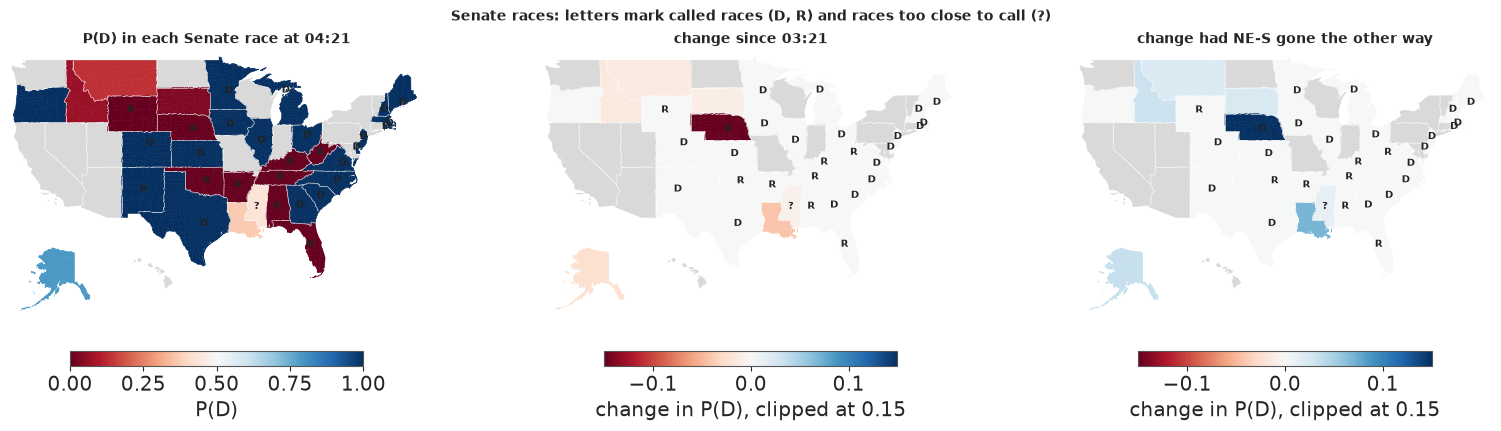

In [13]:
FIPS = {"01": "AL", "02": "AK", "04": "AZ", "05": "AR", "06": "CA", "08": "CO", "09": "CT", "10": "DE",
        "11": "DC", "12": "FL", "13": "GA", "15": "HI", "16": "ID", "17": "IL", "18": "IN", "19": "IA",
        "20": "KS", "21": "KY", "22": "LA", "23": "ME", "24": "MD", "25": "MA", "26": "MI", "27": "MN",
        "28": "MS", "29": "MO", "30": "MT", "31": "NE", "32": "NV", "33": "NH", "34": "NJ", "35": "NM",
        "36": "NY", "37": "NC", "38": "ND", "39": "OH", "40": "OK", "41": "OR", "42": "PA", "44": "RI",
        "45": "SC", "46": "SD", "47": "TN", "48": "TX", "49": "UT", "50": "VT", "51": "VA", "53": "WA",
        "54": "WV", "55": "WI", "56": "WY"}


def place(ring, st):
    """Lower 48 as longitude and latitude; Alaska and Hawaii moved and scaled into the corner (as in E94)."""
    x, y = ring[:, 0], ring[:, 1]
    if st == "AK":
        x, y = -118 + (x + 152) * 0.2, 25 + (y - 63) * 0.35
    elif st == "HI":
        x, y = -104 + (x + 157), 25 + (y - 20.5)
    return np.c_[x, y]


rings, ring_state = [], []
for ft in json.load(open(data.path("us_counties_geojson")))["features"]:
    st = FIPS.get(ft["properties"]["STATE"])
    geom = ft["geometry"]
    for poly in ([geom["coordinates"]] if geom["type"] == "Polygon" else geom["coordinates"]):
        ring = np.asarray(poly[0], float)
        if st and not (st == "AK" and ring[:, 0].max() > 0):      # Aleutians past 180 degrees dropped
            rings.append(place(ring, st))
            ring_state.append(st)
ring_state = np.array(ring_state)
seen_ = {}
for ring, st in zip(rings, ring_state):                          # state borders, no GIS dissolve (E89)
    r_ = np.round(ring, 3)
    for a_, b_ in zip(map(tuple, r_[:-1]), map(tuple, r_[1:])):
        seen_.setdefault((a_, b_) if a_ < b_ else (b_, a_), set()).add(st)
borders = [e for e, g_ in seen_.items() if len(g_) > 1]
sen_of = {tm.state[i]: i for i in sen_rows}
ring_race = np.array([sen_of.get(s, -1) for s in ring_state])
centre = {s: np.median(np.vstack([r for r, s_ in zip(rings, ring_state) if s_ == s]), 0) for s in sen_of}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
cmap = plt.get_cmap("RdBu").copy()
cmap.set_bad(LIGHT)
panels = ((axes[0], S0["pD"], plt.Normalize(0, 1), INFO, f"P(D) in each Senate race at {AS_OF[-5:]}", "P(D)"),
          (axes[1], S_LAST["pD"] - S_PREV["pD"], plt.Normalize(-0.15, 0.15), INFO,
           f"change since {prev_lab}", "change in P(D), clipped at 0.15"),
          (axes[2], S_FLIP["pD"] - S0["pD"], plt.Normalize(-0.15, 0.15), INFO_F,
           f"change had {flip} gone the other way", "change in P(D), clipped at 0.15"))
for ax, v, nrm, inf_, title, lab in panels:
    vals = np.ma.masked_array(np.where(ring_race >= 0, v[np.maximum(ring_race, 0)], 0.0), ring_race < 0)
    ax.add_collection(PolyCollection(rings, array=vals, cmap=cmap, norm=nrm, edgecolor="face", linewidth=0.4))
    ax.add_collection(LineCollection(borders, color="white", lw=0.5))
    for race, lo, hi in inf_:
        if race.endswith("-S"):
            mark = "D" if np.isinf(hi) else ("R" if np.isinf(lo) else "?")
            ax.text(*centre[tm.state[RACE[race]]], mark, ha="center", va="center", fontsize=7, weight="bold",
                    color=INK)
    ax.set_xlim(-125, -66)
    ax.set_ylim(17, 50)
    ax.set_aspect(1 / np.cos(np.radians(38)))
    ax.set_axis_off()
    ax.set_title(title, fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(nrm, cmap), ax=ax, orientation="horizontal", fraction=0.05, pad=0.02, label=lab)
fig.suptitle("Senate races: letters mark called races (D, R) and races too close to call (?)", fontsize=10);

The left map is the state of the Senate race by race; called states carry their letter. The middle map
is the latest batch's effect on the races still open: a call that runs ahead of the forecast for one
party tints the whole map that party's colour, most strongly in the states whose races were close. The
right map is the same picture for the counterfactual. These maps show only the Senate. The counties are
drawn only to build the states.

### 4.1 The House, district by district

The House gets the same treatment with its own geography: the 435 districts as the Census Bureau drew
them for the 120th Congress. These are the lines on tonight's ballots, including the maps that Texas,
California and others redrew in the middle of the decade. Each district is shaded by its latest P(D),
and called districts are outlined in black. A map of districts misleads in one known way. The districts
hold the same number of people, not the same area, so the big rural districts look important and the
cities, where most of the close suburban seats sit, shrink to specks. The insets enlarge four of those
metro areas. The 19 districts that only one party is contesting are not in the model; they are
shaded as certain for that party.

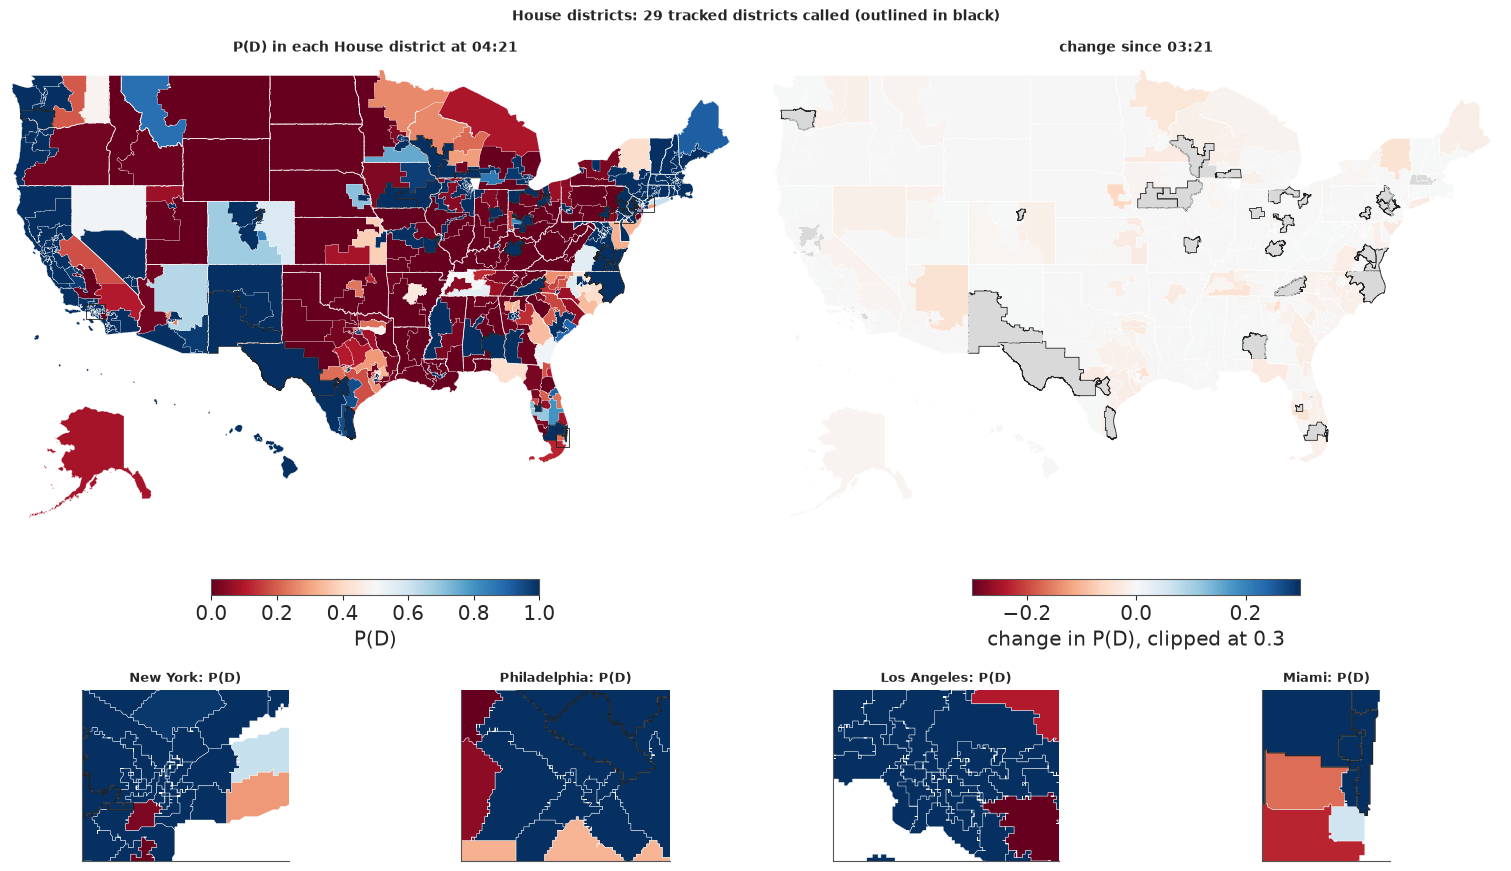

In [14]:
cd = np.load(data.path("e95_cd120_districts"))
d_rings = [place(cd["xy"][a:b].astype(float), c[:2]) for a, b, c in zip(cd["start"][:-1], cd["start"][1:], cd["code"])]
d_idx = np.array([RACE.get(c, -1) for c in cd["code"]])
r26 = pd.read_csv(data.path("e94_races")).query("cycle == 2026 and office == 'H'").set_index("race")
d_fixed = np.array([float(r26.d_name.notna()[c]) for c in cd["code"]])   # uncontested: not modelled, certain


def by_district(v, fixed):
    return np.where(d_idx >= 0, np.asarray(v)[np.maximum(d_idx, 0)], fixed)


called_h = {race for race, lo, hi in INFO if not race.endswith("-S") and (np.isinf(lo) or np.isinf(hi))}
d_called = np.array([c in called_h for c in cd["code"]])
INSETS = (("New York", (-74.6, -73.0, 40.3, 41.3)), ("Philadelphia", (-76.2, -74.6, 39.6, 40.6)),
          ("Los Angeles", (-118.9, -117.3, 33.5, 34.5)), ("Miami", (-80.9, -79.9, 25.4, 26.6)))

fig = plt.figure(figsize=(15, 8.6))
gs = fig.add_gridspec(2, 4, height_ratios=[3.2, 1], hspace=0.05, wspace=0.08)
panels = ((fig.add_subplot(gs[0, :2]), S0["pD"], plt.Normalize(0, 1), f"P(D) in each House district at {AS_OF[-5:]}",
           "P(D)"),
          (fig.add_subplot(gs[0, 2:]), S_LAST["pD"] - S_PREV["pD"], plt.Normalize(-0.3, 0.3),
           f"change since {prev_lab}", "change in P(D), clipped at 0.3"))
for k, (ax, v, nrm, title, lab) in enumerate(panels):
    ax.add_collection(PolyCollection(d_rings, array=(by_district(v, d_fixed) if k == 0 else
                                            np.ma.masked_array(by_district(v, 0.0), d_called | (d_idx < 0))), cmap=cmap, norm=nrm, edgecolor="white", linewidth=0.15))
    ax.add_collection(PolyCollection([r for r, c_ in zip(d_rings, d_called) if c_], facecolor="none",
                                     edgecolor=INK, linewidth=0.6))
    ax.add_collection(LineCollection(borders, color="white", lw=0.6))
    ax.set_xlim(-125, -66)
    ax.set_ylim(17, 50)
    ax.set_aspect(1 / np.cos(np.radians(38)))
    ax.set_axis_off()
    ax.set_title(title, fontsize=10)
    fig.colorbar(plt.cm.ScalarMappable(nrm, cmap), ax=ax, orientation="horizontal", fraction=0.03, pad=0.0,
                 shrink=0.5, label=lab)
    if k == 0:
        for name, (x0, x1, y0, y1) in INSETS:
            ax.add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=INK, lw=0.6))
for j, (name, (x0, x1, y0, y1)) in enumerate(INSETS):
    ax = fig.add_subplot(gs[1, j])
    ax.add_collection(PolyCollection(d_rings, array=by_district(S0["pD"], d_fixed), cmap=cmap, norm=plt.Normalize(0, 1),
                                     edgecolor="white", linewidth=0.3))
    ax.add_collection(PolyCollection([r for r, c_ in zip(d_rings, d_called) if c_], facecolor="none",
                                     edgecolor=INK, linewidth=0.9))
    ax.set_xlim(x0, x1)
    ax.set_ylim(y0, y1)
    ax.set_aspect(1 / np.cos(np.radians((y0 + y1) / 2)))
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title(f"{name}: P(D)", fontsize=9)
fig.suptitle(f"House districts: {len(called_h)} tracked districts called (outlined in black)",
             fontsize=10);

Read the left map for where the House stands, and the right one for what the latest batch of calls did to
the districts not yet called (called and uncontested districts are grey there). Because each call is read partly as news about the shared polling error, a
batch that runs ahead of the forecast for one party tints every open district toward that party, not
only the neighbours of the called seats. The outlines show how few of the called House races the log
holds: only the competitive ones are logged, and safe seats carry no information.

## 5 · What is still out

For every race still in doubt we can ask the question a viewer asks next: if the Democrat wins this one,
what happens to control, and if the Republican does? With one simulated election per draw these are
conditional frequencies: among the draws in which the Democrat wins race $r$, the share in which the
Democrats control the Senate. The difference between the two answers is how much the race matters. It
mixes two things, the seat itself and what winning it says about the polling error, which is why a race
can matter even when its seat is not the one that decides control.

In [15]:
called = {r for r, *_ in INFO if r not in closes}
open_ = [i for i in range(len(tm)) if tm.race[i] not in called and 0.05 < S0["pD"][i] < 0.95]


def cond(S, i, need, chamber):
    dwin = S["won"][:, i]
    hit = S[chamber] >= need
    return S["w"][dwin] @ hit[dwin] / S["w"][dwin].sum(), S["w"][~dwin] @ hit[~dwin] / S["w"][~dwin].sum()


rows = []
for i in open_:
    hD, hR = cond(S0, i, 218, "H")
    sD, sR = cond(S0, i, 51, "S")
    rows.append({"race": tm.race[i], "office": tm.office[i], "P(D)": S0["pD"][i], "House if D": hD,
                 "House if R": hR, "Senate if D": sD, "Senate if R": sR})
watch = pd.DataFrame(rows)
watch["House swing"] = watch["House if D"] - watch["House if R"]
watch["Senate swing"] = watch["Senate if D"] - watch["Senate if R"]
print(f"{len(watch)} races still uncertain (0.05 < P(D) < 0.95). Senate races:")
print(watch[watch.office == "S"].sort_values("Senate swing", ascending=False).round(3).to_string(index=False))
print("the House races that move House control most:")
print(watch[watch.office == "H"].sort_values("House swing", ascending=False).head(12).round(3).to_string(index=False))

96 races still uncertain (0.05 < P(D) < 0.95). Senate races:
race office  P(D)  House if D  House if R  Senate if D  Senate if R  House swing  Senate swing
MT-S      S 0.135         1.0         1.0          1.0          1.0          0.0           0.0
ID-S      S 0.069         1.0         1.0          1.0          1.0          0.0           0.0
AK-S      S 0.787         1.0         1.0          1.0          1.0         -0.0          -0.0
MS-S      S 0.431         1.0         1.0          1.0          1.0         -0.0          -0.0
LA-S      S 0.371         1.0         1.0          1.0          1.0         -0.0          -0.0
the House races that move House control most:
 race office  P(D)  House if D  House if R  Senate if D  Senate if R  House swing  Senate swing
FL-27      H 0.601         1.0         1.0          1.0          1.0          0.0           0.0
NY-01      H 0.616         1.0         1.0          1.0          1.0          0.0           0.0
NE-01      H 0.709         1.0     

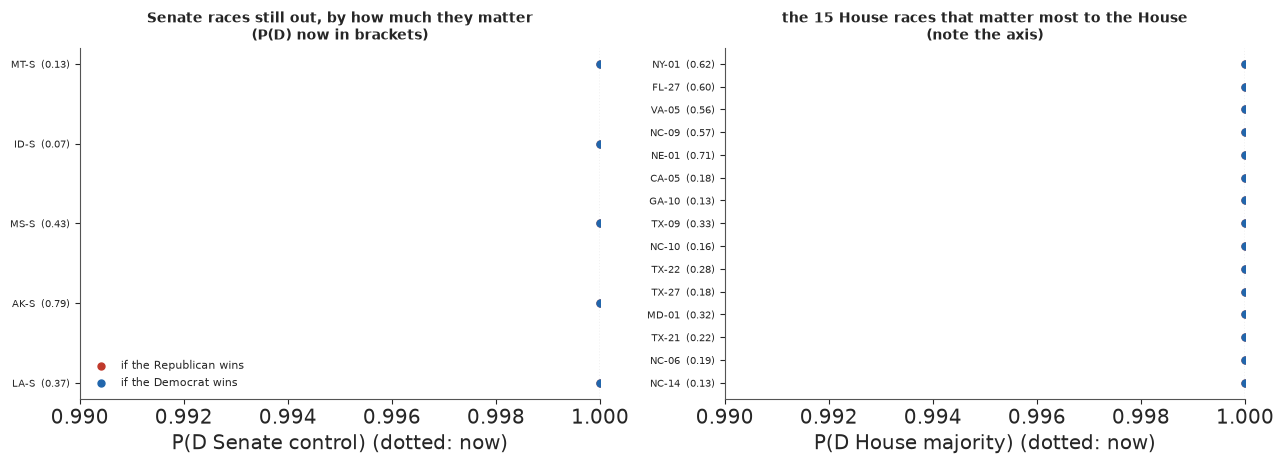

In [16]:
ws = watch[watch.office == "S"].sort_values("Senate swing")
wh = watch[watch.office == "H"].sort_values("House swing").tail(15)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, w_, a, b, lab, base_ in ((axes[0], ws, "Senate if R", "Senate if D", "P(D Senate control)", S0["P(Senate)"]),
                                 (axes[1], wh, "House if R", "House if D", "P(D House majority)", S0["P(House)"])):
    y_ = np.arange(len(w_))
    ax.hlines(y_, w_[a], w_[b], color=LIGHT, lw=3)
    ax.scatter(w_[a], y_, color=R_C, s=25, label="if the Republican wins", zorder=3)
    ax.scatter(w_[b], y_, color=D_C, s=25, label="if the Democrat wins", zorder=3)
    ax.axvline(base_, color=INK, lw=0.8, ls=":")
    ax.set_yticks(y_, [f"{r}  ({p:.2f})" for r, p in zip(w_.race, w_["P(D)"])], fontsize=7)
    ax.set_xlabel(lab + " (dotted: now)")
    lo_ = float(min(w_[a].min(), base_)) if len(w_) else 0.0
    ax.set_xlim(max(0.0, lo_ - 0.1 * (1 - lo_) - 0.01), 1.0)
axes[0].legend(fontsize=8, loc="lower left")
axes[0].set_title("Senate races still out, by how much they matter\n(P(D) now in brackets)", fontsize=10)
axes[1].set_title("the 15 House races that matter most to the House\n(note the axis)", fontsize=10)
fig.tight_layout();

Two patterns hold while control is in doubt. A race matters most when it is likely to go one way and its
loss would be a surprise: a Democratic loss in a race the Democrats were expected to win removes a seat
they were counting on and says the polls were off. So the Senate races at the top of the left panel are
often not the closest ones, but the likely Democratic wins that the Senate majority counts on. On the
right, no single House race moves House control by much, because the majority is a sum of hundreds of
races; the races at the top are likely Democratic seats whose loss would signal a broader miss. Watch
the axis: it starts well above zero. Once control of a chamber is all but certain, as both are at the
latest snapshot, the two answers for every race coincide and the panels collapse onto the dotted line:
no race still out can change control, only the size of the majority.

## 6 · Silences and partial counts

### 6.1 "Too close to call" is data

A race that is not called when its polls close says something too. The AP waits when the count could
still go either way, so an uncalled race is likely to be close. How close is a judgement: we read "too
close" as $|m_r| < 3$ points and try 1.5 and 5 as well. The choice is ours, not the data's, so the
table shows how much it matters at the latest snapshot. It applies only while a race is listed as too
close; once the race is called, the call replaces it, and the log keeps both.

In [17]:
rows = []
for c in (None, 1.5, 3.0, 5.0):
    cl = calls if c is not None else calls[calls.status != "too close"]
    S = reweighted(info_from(cl, c if c is not None else CLOSE))
    row = {"too-close races read as": "no information" if c is None else f"|margin| < {c}", "ESS": round(S["ess"])}
    row.update({f"{r} P(D)": round(S["pD"][RACE[r]], 3) for r in closes})
    row.update({"P(D Senate)": round(S["P(Senate)"], 3), "P(D House)": round(S["P(House)"], 3),
                "polling error": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*wq(S["bias"], S["w"]))})
    rows.append(row)
print("races too close to call now:", closes or "none")
print(pd.DataFrame(rows).to_string(index=False))
ever = log[log.status == "too close"].race.unique().tolist()
print("races listed as too close at some snapshot:", ever or "none")

races too close to call now: ['MS-S']
too-close races read as  ESS  MS-S P(D)  P(D Senate)  P(D House)     polling error
         no information    5      0.049          1.0         1.0 -3.9 [-4.8, -3.3]
         |margin| < 1.5    6      0.419          1.0         1.0 -4.4 [-7.5, -3.3]
         |margin| < 3.0    6      0.343          1.0         1.0 -4.4 [-7.5, -3.3]
         |margin| < 5.0    6      0.256          1.0         1.0 -4.4 [-7.5, -3.3]
races listed as too close at some snapshot: ['FL-S', 'MS-S']


When no race is listed as too close, every row of the table is the same. When one is, read the first
row against the others. A race that is too close in a state one party was expected to win comfortably
says that party is not winning there by the margin the forecast expected, which points to a polling
error against it, and through the shared error that moves every race. The narrower the reading, the
stronger the pull.

Florida showed how much this can matter and how fragile it is. In the 20:20 snapshot its Senate race
was too close to call. Read as $|m_r| < 3$, that one silence moved the chance of a Democratic Senate
from 0.82 (calls only) to 0.93, more than all the calls together, because Moody had been expected to win
by about five points. Half an hour later Fox called Florida for Moody, the interval became a one-sided
call the forecast had expected, and most of that rise went away; the replay in section 3.1 shows the
spike. An uncalled race is evidence, but how much depends on an assumption about what the silence means.

### 6.2 Partial counts, and the order ballots are counted

Many pages give a running count: Ossoff led 64-36 with 56% of the expected vote in. It is tempting to
use it, and wrong to use it at face value. Ballots are counted in batches whose order depends on each
state's rules, and the batches lean differently, because the voters who vote early, by mail and on the
day are not the same people. In Georgia, Florida and North Carolina the early and mail ballots, which
lean Democratic, are counted and reported first, so the count starts blue and drifts red as
election-day precincts come in; Ossoff's 64-36 overstates his final margin by an amount nobody knows on
the night. In Pennsylvania and Wisconsin mail ballots may not be processed before election day and often
come last, so the drift runs the other way; in Arizona, Nevada and California, late-arriving mail and
provisional ballots are counted for days. The same share counted means different things in different
states.

So the log keeps partial counts, but a margin enters only once a race is at least 95% counted, and even
then the ballots still out may differ from those counted. If the outstanding share $u$ could lean up to
$k = 30$ points differently from the counted ballots, the final margin could differ from the count by
about $k\,u$, so a near-final margin enters with sd $\sqrt{0.5^2 + (k u)^2}$: 1.5 points at 95% counted,
0.5 when the count is complete.

### 6.3 The margin is the message

A call tells us the sign of one margin; the margin tells us much more. The cell takes the closest
Senate race called so far and refits the model for a range of final margins on the winner's side, each
treated as a complete count, on top of all the night's calls. It also reports the ESS that reweighting
would have had. The answer is a curve, not a number, while the final margin is unknown.

In [18]:
sc = calls[(calls.status == "called") & calls.race.str.endswith("-S")]
SWEEP = sc.assign(gap=(sc.pD - 0.5).abs()).sort_values("gap").race.iloc[0]
sgn = 1.0 if calls.set_index("race").winner[SWEEP] == "D" else -1.0
FINALS = sgn * np.array([1.0, 4.0, 8.0, 14.0])
others = [m_ for m_ in MARG if m_[0] != SWEEP]
rows, sweep = [], {}
t0 = time.time()
for y in FINALS:
    S = refit(INFO, [(SWEEP, y, tau_m(100))] + others)
    lw = np.log(weights(E, INFO)) + norm.logpdf(y, E["mu"][:, RACE[SWEEP]], tau_m(100))
    w_ = np.exp(lw - lw.max())
    sweep[y] = S
    rows.append({f"{SWEEP} final margin": f"{y:+.0f}", "P(D House)": round(S["P(House)"], 3),
                 "P(D Senate)": round(S["P(Senate)"], 3),
                 "N": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*np.quantile(S["N"], [0.05, 0.5, 0.95])),
                 "polling error": "{1:+.1f} [{0:+.1f}, {2:+.1f}]".format(*np.quantile(S["bias"], [0.05, 0.5, 0.95])),
                 "reweighting ESS": round(ess(w_ / w_.sum()), 1), "divergences": S["diag"]["divergences"]})
TIMES["margin refits"] = time.time() - t0
print(f"{SWEEP}: eve median {fz.pred[SWEEP]:+.1f} (80% interval {fz.q10[SWEEP]:+.1f} to {fz.q90[SWEEP]:+.1f}), "
      f"called for the {'Democrat' if sgn > 0 else 'Republican'}")
print(pd.DataFrame(rows).to_string(index=False))

IA-S: eve median +0.8 (80% interval -5.8 to +7.2), called for the Democrat
IA-S final margin  P(D House)  P(D Senate)                    N     polling error  reweighting ESS  divergences
               +1         1.0          1.0 +13.7 [+11.3, +16.1] -4.6 [-6.9, -2.3]              1.2            0
               +4         1.0          1.0 +13.9 [+11.5, +16.3] -4.8 [-7.1, -2.6]              1.1            0
               +8         1.0          1.0 +14.2 [+11.7, +16.7] -5.2 [-7.5, -2.9]              1.0            0
              +14         1.0          1.0 +14.8 [+12.2, +17.3] -5.7 [-8.1, -3.3]              1.0            0


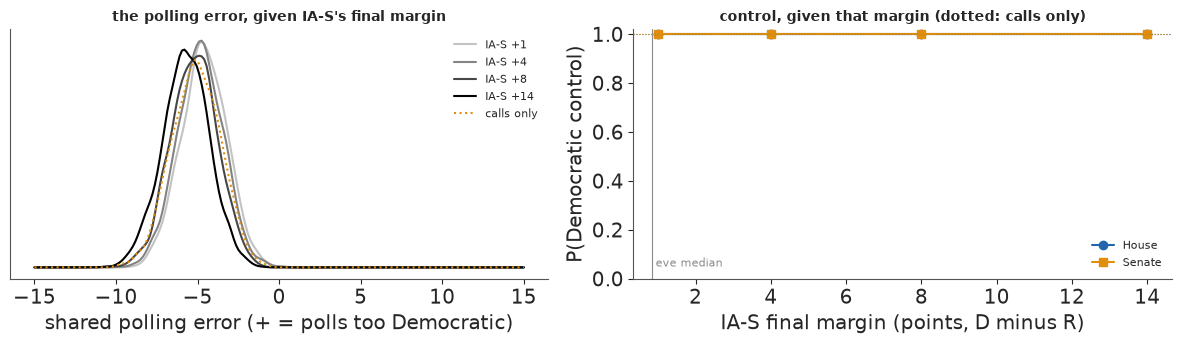

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ax = axes[0]
for y, c in zip(FINALS, plt.cm.Greys(np.linspace(0.35, 1, len(FINALS)))):
    ax.plot(gx, gaussian_kde(sweep[y]["bias"])(gx), color=c, label=f"{SWEEP} {y:+.0f}")
ax.plot(gx, gaussian_kde(S_CALLS["bias"])(gx), color=GOLD, ls=":", label="calls only")
ax.set_xlabel("shared polling error (+ = polls too Democratic)")
ax.set_yticks([])
ax.legend(fontsize=8)
ax.set_title(f"the polling error, given {SWEEP}'s final margin", fontsize=10)
ax = axes[1]
ax.plot(FINALS, [sweep[y]["P(House)"] for y in FINALS], "o-", color=D_C, label="House")
ax.plot(FINALS, [sweep[y]["P(Senate)"] for y in FINALS], "s-", color=GOLD, label="Senate")
ax.axhline(S_CALLS["P(House)"], color=D_C, ls=":", lw=0.8)
ax.axhline(S_CALLS["P(Senate)"], color=GOLD, ls=":", lw=0.8)
ax.axvline(fz.pred[SWEEP], color=MUTED, lw=0.8)
ax.text(fz.pred[SWEEP], 0.05, " eve median", color=MUTED, fontsize=8)
ax.set_xlabel(f"{SWEEP} final margin (points, D minus R)")
ax.set_ylabel("P(Democratic control)")
ax.set_ylim(0, 1.02)
ax.legend(fontsize=8, loc="lower right")
ax.set_title("control, given that margin (dotted: calls only)", fontsize=10)
fig.tight_layout();

The margin matters in a way the call did not. Across the range, the polling error moves by several
points and the chance of each chamber with it: a winner who runs ahead of the forecast says the polls
understated their party, and every race still out moves toward it. The reweighting ESS column is the
failure in numbers: conditioning on a margin known to within a point keeps only the eve draws that
happened to land near it: a few dozen at best, and only a handful late in the night, when the calls
have already narrowed the draws. A margin is strong data, and strong data need a refit.

## 7 · Where the night stands

The bulletin below is written by the code from the latest snapshot, so it is current whenever the
notebook is rebuilt.

In [20]:
def iv(v, f, w=None):
    q_ = wq(v, w) if w is not None else np.quantile(v, [0.05, 0.5, 0.95])
    return f"{q_[1]:{f}} ({q_[0]:{f}} to {q_[2]:{f}})"


ncall = int((calls.status == "called").sum())
surpr = calls[calls.status == "called"].sort_values("surprise", ascending=False).head(3)
top_s = watch[watch.office == "S"].sort_values("Senate swing", ascending=False).head(3)
mv_top = mv.reindex(mv.change.abs().sort_values(ascending=False).index).head(5)
text = f"""**As of {AS_OF} ET**: {ncall} tracked races called, {len(closes)} too close to call
({", ".join(closes) or "none"}){"" if not MARG else
f", {len(MARG)} counted to at least {FINAL}% ({', '.join(r for r, *_ in MARG)})"}.
New since {prev_lab}: {", ".join(f"{r.race} {r.winner if r.status == 'called' else '(too close)'}"
                                 for r in new_rows.itertuples())}.

* **House:** P(Democratic majority) {S0['P(House)']:.2f} (eve {EVE['P(House)']:.2f}; the latest rows moved it by
  {S_LAST['P(House)'] - S_PREV['P(House)']:+.3f}); Democratic seats {iv(S0['H'], '.0f')}.
* **Senate:** P(Democratic control) {S0['P(Senate)']:.2f} (eve {EVE['P(Senate)']:.2f}; the latest rows moved it by
  {S_LAST['P(Senate)'] - S_PREV['P(Senate)']:+.3f}); Democratic-caucus seats {iv(S0['S'], '.0f')}.
* **The polls:** shared polling error {iv(S0['bias'], '+.1f')} points (eve {iv(EVE['bias'], '+.1f')}); national
  House margin {iv(S0['N'], '+.1f')} (eve {iv(EVE['N'], '+.1f')}).
* **Most surprising calls so far:** {"; ".join(f"{r_} for the {'Democrat' if w_ == 'D' else 'Republican'} "
  f"(eve chance {p_:.3f})" for r_, w_, p_ in zip(surpr.race, surpr.winner, surpr["P(result)"]))}.
* **Races still out that moved most since {prev_lab}** ({"two refits compared" if MOVE_HOW == "refit" else "reweighted draws"}): {"; ".join(f"{r.race} {r.previous:.2f} to {r.latest:.2f}"
  for r in mv_top.itertuples())}.
* **Had {flip} gone the other way:** P(D House) {S_FLIP['P(House)']:.2f}, P(D Senate) {S_FLIP['P(Senate)']:.2f}.
* **Senate races to watch:** {"; ".join(f"{r.race} (P(D) {r._3:.2f}; control {r._6:.2f} if D, {r._7:.2f} if R)"
  for r in top_s.itertuples())}.
* Reweighting and refit agree to {gap.max():.3f} in the race chances (reweighting ESS
  {S_snap[SNAPS[-1]]['ess']:.0f} of {len(EVE['w'])}).
"""
display(Markdown(text))


def gauge(ax, p, p_eve, label):
    """A half-dial from a certain Republican win (left) to a certain Democratic win (right)."""
    rb = plt.get_cmap("RdBu")
    for k in range(90):
        ax.add_patch(Wedge((0, 0), 1, 180 - 2 * (k + 1), 180 - 2 * k, width=0.28, color=rb(0.08 + 0.84 * k / 89)))
    for q, a in ((p_eve, GOLD), (p, INK)):
        ang = np.radians(180 * (1 - q))
        if a == GOLD:
            ax.plot([0.68 * np.cos(ang), 1.06 * np.cos(ang)], [0.68 * np.sin(ang), 1.06 * np.sin(ang)], color=GOLD, lw=3)
        else:
            ax.plot([0, 0.86 * np.cos(ang)], [0, 0.86 * np.sin(ang)], color=INK, lw=4, solid_capstyle="round")
    ax.add_patch(Circle((0, 0), 0.06, color=INK))
    pct = "> 99%" if p > 0.995 else ("< 1%" if p < 0.005 else f"{100 * p:.0f}%")
    ax.text(0, -0.3, pct, ha="center", va="center", fontsize=34, weight="bold", color=D_C if p >= 0.5 else R_C)
    ax.text(0, -0.58, label, ha="center", va="center", fontsize=11, color=INK)
    ax.text(-1.0, -0.1, "R", ha="center", fontsize=12, weight="bold", color=R_C)
    ax.text(1.0, -0.1, "D", ha="center", fontsize=12, weight="bold", color=D_C)
    ax.set_xlim(-1.2, 1.2)
    ax.set_ylim(-0.72, 1.12)
    ax.set_aspect("equal")
    ax.set_axis_off()


def seat_bars(ax, v, need, total, label, w=None, xlim=None):
    w = np.full(len(v), 1 / len(v)) if w is None else w
    e = np.arange(v.min() - 0.5, v.max() + 1.5)
    cnt, _ = np.histogram(v, e, weights=w)
    mid = e[:-1] + 0.5
    ax.bar(mid, cnt, width=1.0, color=np.where(mid >= need, D_C, R_C), alpha=0.8)
    ax.axvline(need - 0.5, color=INK, lw=1, ls=":")
    if xlim is not None:
        ax.set_xlim(*xlim)
    lo, med, hi = np.round(wq(v.astype(float), w))
    spare = int(round(med)) - need
    how = (f"{spare} more than the {need} a majority needs" if spare > 0 else
           "exactly a majority" if spare == 0 else f"{-spare} short of the {need} a majority needs")
    ax.set_title(f"{label}: {med:.0f} Democratic seats (90%: {lo:.0f} to {hi:.0f}),\n{how}", fontsize=10)
    ax.set_yticks([])
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.set_xlabel("Democratic seats (dotted: majority line)")


fig = plt.figure(figsize=(12, 5.8))
gs_ = fig.add_gridspec(2, 2, height_ratios=[1.25, 0.75], hspace=0.05)
gauge(fig.add_subplot(gs_[0, 0]), S0["P(House)"], EVE["P(House)"], "chance the Democrats win the House")
gauge(fig.add_subplot(gs_[0, 1]), S0["P(Senate)"], EVE["P(Senate)"], "chance the Democrats control the Senate")
seat_bars(fig.add_subplot(gs_[1, 0]), S0["H"], 218, 435, "House")
seat_bars(fig.add_subplot(gs_[1, 1]), S0["S"], 51, 100, "Senate (34 seats not up included)")
fig.suptitle(f"Election night, as of {AS_OF[-5:]} ET on 3 November: {ncall} tracked races called "
             f"(eve forecast: House {EVE['P(House)']:.0%}, Senate {EVE['P(Senate)']:.0%}, gold ticks)", fontsize=12)
GLANCE.update(fig)
plt.close(fig)

**As of 2026-11-04 04:21 ET**: 57 tracked races called, 1 too close to call
(MS-S), 1 counted to at least 95% (MS-S).
New since 03:21: NE-S R.

* **House:** P(Democratic majority) 1.00 (eve 0.95; the latest rows moved it by
  +0.000); Democratic seats 272 (261 to 288).
* **Senate:** P(Democratic control) 1.00 (eve 0.80; the latest rows moved it by
  +0.000); Democratic-caucus seats 56 (54 to 57).
* **The polls:** shared polling error -5.2 (-7.6 to -2.9) points (eve +1.0 (-3.7 to +5.8)); national
  House margin +14.2 (+11.7 to +16.8) (eve +8.0 (+3.2 to +12.8)).
* **Most surprising calls so far:** IN-05 for the Democrat (eve chance 0.180); OH-15 for the Democrat (eve chance 0.200); TX-23 for the Democrat (eve chance 0.261).
* **Races still out that moved most since 03:21** (two refits compared): NE-01 0.77 to 0.71; GA-07 0.39 to 0.34; TN-09 0.59 to 0.55; TX-09 0.38 to 0.33; NY-21 0.46 to 0.41.
* **Had NE-S gone the other way:** P(D House) 1.00, P(D Senate) 1.00.
* **Senate races to watch:** MT-S (P(D) 0.13; control 1.00 if D, 1.00 if R); ID-S (P(D) 0.07; control 1.00 if D, 1.00 if R); AK-S (P(D) 0.79; control 1.00 if D, 1.00 if R).
* Reweighting and refit agree to 0.426 in the race chances (reweighting ESS
  6 of 4000).


### 7.1 The night as it came in

The same gauges, one frame per snapshot, from the eve forecast to the latest; drag the slider or press
play. Each frame is the forecast with the rows logged up to that time. A snapshot whose reweighted
draws keep an ESS of at least 1,000 is drawn from the reweighted eve draws; one below that is refitted
by NUTS, because a seat histogram resting on a hundred effective draws is mostly noise. The latest frame
is the refit that the gauges at the top show.

In [21]:
from matplotlib import animation
from IPython.display import HTML

t0 = time.time()
FRAMES = [("eve", EVE)]
for t in SNAPS:
    st_ = state_at(t)
    if t == SNAPS[-1]:
        S_ = S0
    elif t in REFITTED:
        S_ = REFITTED[t]
    elif S_snap[t]["ess"] >= 1000:
        S_ = S_snap[t]
    else:
        m_ = margins_from(st_)
        S_ = refit(info_from(st_), m_)
    FRAMES.append((t.strftime("%H:%M"), S_))
TIMES["slider refits"] = time.time() - t0
h_lim = (min(np.quantile(S_["H"], 0.001) for _, S_ in FRAMES) - 3, max(np.quantile(S_["H"], 0.999) for _, S_ in FRAMES) + 3)
s_lim = (min(S_["S"].min() for _, S_ in FRAMES) - 1, max(S_["S"].max() for _, S_ in FRAMES) + 1)
fig = plt.figure(figsize=(12, 5.8))
gs_ = fig.add_gridspec(2, 2, height_ratios=[1.25, 0.75], hspace=0.05)
axs = [fig.add_subplot(gs_[0, 0]), fig.add_subplot(gs_[0, 1]), fig.add_subplot(gs_[1, 0]), fig.add_subplot(gs_[1, 1])]
title = fig.suptitle("", fontsize=12)


def show_frame(k):
    lab, S_ = FRAMES[k]
    for ax in axs:
        ax.clear()
    gauge(axs[0], S_["P(House)"], EVE["P(House)"], "chance the Democrats win the House")
    gauge(axs[1], S_["P(Senate)"], EVE["P(Senate)"], "chance the Democrats control the Senate")
    seat_bars(axs[2], S_["H"], 218, 435, "House", S_["w"], h_lim)
    seat_bars(axs[3], S_["S"], 51, 100, "Senate (34 not up included)", S_["w"], s_lim)
    n_ = 0 if lab == "eve" else int((state_at(SNAPS[k - 1]).status == "called").sum())
    title.set_text("The eve forecast (gold ticks)" if lab == "eve" else
                   f"As of {lab} ET: {n_} tracked races called (gold ticks: the eve)")
    return axs


show_frame(0)
anim = animation.FuncAnimation(fig, show_frame, frames=len(FRAMES), interval=1200)
plt.close(fig)
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)
    anim_html = anim.to_jshtml(default_mode="once")
print(f"{len(FRAMES)} frames: " + ", ".join(f"{lab} House {S_['P(House)']:.2f} Senate {S_['P(Senate)']:.2f}"
                                           for lab, S_ in FRAMES))
HTML(anim_html)

12 frames: eve House 0.95 Senate 0.80, 20:20 House 0.99 Senate 0.93, 20:50 House 0.99 Senate 0.87, 21:28 House 0.99 Senate 0.87, 23:18 House 1.00 Senate 1.00, 23:45 House 1.00 Senate 1.00, 00:18 House 1.00 Senate 1.00, 00:30 House 1.00 Senate 1.00, 01:21 House 1.00 Senate 1.00, 02:21 House 1.00 Senate 1.00, 03:21 House 1.00 Senate 1.00, 04:21 House 1.00 Senate 1.00


In [22]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'eve fit': 24, 'latest refits': 232, 'counterfactual refit': 198, 'margin refits': 536, 'slider refits': 351, 'total': 1363}


## Summary

* **A call moves the map in proportion to its surprise.** The night's first call, Georgia for Ossoff,
  had been given a 0.994 chance; it carried 0.007 nats and moved the chance of a Democratic Senate from
  0.801 to 0.804. A Collins win, at 0.0065, would have moved both chambers by tens of points. The calls
  that reshape the election are the ones the forecast did not expect, and the replay in section 3 shows
  which they were.
* **A call is an interval on the margin.** With the race's own noise integrated out, its likelihood is a
  normal CDF of the race's mean margin; "too close to call" is an interval around zero, and its reading
  is an assumption that can be the night's largest effect, as Florida's silence was for half an hour.
* **Reweighting is exact but fragile.** Weighting the frozen draws by the likelihood of the calls agrees
  with a NUTS refit with a `Potential` to a few thousandths per race on average while the ESS stays in
  the hundreds or more. A surprising result or a margin known to a point needs the refit, which takes
  half a minute.
* **Partial counts lean by the order ballots are counted.** Early and mail ballots come first in some
  states and last in others, so a running margin is not a sample of the final one. Margins enter only
  from 95% counted, with an sd that grows with the share still out; a final margin then says much more
  than the call did.
* **Conditional forecasts tell you what to watch.** For each race still out, the chance of control if
  either side wins it measures how much it matters, through the seat and through what it says about the
  polls. While control was in doubt, Senate control hung most on the likely Democratic wins the
  majority counted on, and no single House race moved House control by much. By 23:18, with Democratic
  wins in Ohio, Texas and South Carolina, the calls had settled both chambers in the model, and the races
  still out decide only the size of the majorities.

## Try it yourself

1. **Call times as data.** A race called the moment its polls close is not close, and one called at 2
   am is. Record the minutes between poll closing and the call, model the call time as a function of the
   true margin (for example, called at closing when $|m_r|$ exceeds a threshold with a logistic edge), and
   use it in place of the bare call. How much more do the early calls say?
2. **Partial counts with a skew.** Model a partial count as the final margin plus a reporting shift that
   depends on which ballots are counted first, with a state-specific shift learned from 2018 and 2022
   county returns by reporting time. When does a running count become more informative than the call?
3. **Score the night.** Once every race is called, compare the log scores of the frozen forecast and of
   each snapshot's forecast on the races still out at that snapshot. Did updating on the calls improve the
   forecasts of the races that came in later?